<a href="https://colab.research.google.com/github/saulo-albuquerque-phys/GWgpu-jax/blob/py312_modern_jax/examples/referee_response/profiling/COLAB_profiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Run-time profile of the paper's likelihoods (referee comments 4 and 6)

Times every stage of the likelihoods the sampler calls, per evaluation inside a vmapped batch (the
sampler advances `num_delete = 100` chains together, so batch 100 is the operating point), on the GPU
and then on this VM's CPU cores (1, 4 and all cores, via `taskset`), plus JIT compile times:

* **GW170817** (mlgw_bns_jax, 128 s, 23–1500 Hz, H1L1V1): waveform at the 3199 relative-binning bin
  frequencies; RB at fixed (t_c, φ_c); RB + t_c marginalisation (2001 points); RB + t_c + φ_c
  marginalisation (**production**); full band at fixed (t_c, φ_c); full band + t_c + φ_c marginalisation;
  compile + first iteration of the production sampler. These split the production run's 20.6 min into
  waveform, RB overlaps, marginalisation and sampler overhead.
* **GW150914** (mlgw_bbh_jax): (2,2) on 4 s and all 7 modes on 8 s, waveform and full-band likelihood.

Needs the GW170817 frozen data on Drive (`MyDrive/gwjax_referee/gw170817_data/data_gwtc1/`, the same
folder the GW170817 notebook reads); the GW150914 inputs are fetched from GitHub.
Results go to `MyDrive/gwjax_referee/profiling/<timestamp>/`.

**Order:** run the install cell, restart the session, then run everything from the top.
Expect about 1 h in total, most of it in the 1-core CPU pass.

## 1. Install

In [1]:
import importlib.util, os

RUNNING_ON_COLAB  = importlib.util.find_spec("google.colab") is not None
ALREADY_INSTALLED = importlib.util.find_spec("gwgpu_jax") is not None

if RUNNING_ON_COLAB and not ALREADY_INSTALLED:
    # Use Colab's own GPU jax: its CUDA plugin matches the image's CUDA/cuDNN (forcing jax 0.4.31
    # over it crashed the kernel on the Python 3.12 image). Install jax only if it is missing or has
    # no GPU, then freeze jax/TF so the gwgpu_jax install below cannot change them.
    import subprocess as _sp, sys as _sys
    if _sp.run([_sys.executable, "-c", "import jax, sys; sys.exit(jax.default_backend() != 'gpu')"],
               capture_output=True).returncode != 0:
        !pip install -q -U "jax[cuda12]"
    !pip freeze | grep -iE "^(jax|jaxlib|jax-cuda[0-9]+-(plugin|pjrt)|tensorflow|keras|ml.dtypes|numpy)==" > /content/gwjax_constraints.txt
    !python -c "import jax; print('jax', jax.__version__, jax.devices())"

    # Public repo - no token, no authentication. Installs from the default branch.
    !pip install -q -c /content/gwjax_constraints.txt "gwgpu_jax[data,mlgw] @ git+https://github.com/saulo-albuquerque-phys/GWgpu-jax.git@py312_modern_jax"
    # tf2jax <= 0.3.7 uses jax.util.safe_zip (removed in jax 0.7); 0.3.8 is the jax>=0.7 release.
    # It declares TF >= 2.20 but does not check it at run time -> install without deps (Colab TF is
    # frozen); the waveform self-check cell below validates the converted networks.
    if _sp.run([_sys.executable, "-c", "import jax, sys; sys.exit(tuple(map(int, jax.__version__.split('.')[:2])) < (0, 7))"]).returncode == 0:
        !pip install -q --no-deps "tf2jax==0.3.8"

    print("Installed. If JAX was re-pinned: Runtime -> Restart session, then re-run from here.")
else:
    print("gwgpu_jax already importable - skipping install.")


jax 0.7.2 [CudaDevice(id=0)]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.7/906.7 kB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.3/97.3 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.4/373.4 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.7/114.7 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 113.2 MB

In [2]:
# ── Vendored-subrepo bandaid for `gwgpu_jax[mlgw]` on Colab ────────────
# The `mlgw_bbh_jax` Python package is a vendored sub-repo that lives at
#     <gwgpu_jax-install>/mlgw_jax/mlgw_bbh_jax/
# but it's not committed to the GWgpu_jax repo Colab clones from, so the
# wheel built on Colab is missing it. We clone it from the upstream
# `gwgpu_jax_compatible` branch of adrianomascioli/MLGW-JAX, which already
# bakes in the inference-compatibility fixes (Keras 2/3 model-load compat,
# optional keras_tuner / GW_helper imports, JAX-traceable Wigner-d), so
# — unlike the original notebook — NO on-the-fly patch is applied.
#
# Once `mlgw_bbh_jax` is properly committed to the GWgpu_jax repo (or pinned
# as a submodule), this whole cell can be deleted.
import subprocess, sys, shutil
from pathlib import Path

# FIX: Downgrade cryptography to fix pyOpenSSL incompatibility (module 'lib' has no attribute 'GEN_EMAIL')
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "cryptography<44", "pyopenssl"],
    check=True,
)

# 1. Install training-only deps the upstream sub-repo may import. On the
#    gwgpu_jax_compatible branch these imports are already guarded, so this
#    is belt-and-braces and can be dropped if you like.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "keras-tuner"],
    check=True,
)

# 2. Clone the vendored sub-repo (gwgpu_jax_compatible branch) into the
#    gwgpu_jax install path.
import gwgpu_jax
_GW    = Path(gwgpu_jax.__file__).resolve().parent
_DEST  = _GW / "mlgw_jax" / "mlgw_bbh_jax"
_READY = _DEST / ".gwgpu_jax_compatible_ready"

if _READY.exists():
    print(f"✓ mlgw_bbh_jax (gwgpu_jax_compatible) already present at {_DEST}")
else:
    if _DEST.exists():
        shutil.rmtree(_DEST)
    print(f"Cloning mlgw_bbh_jax (gwgpu_jax_compatible) into {_DEST} (~1 GB, ~1–2 min on Colab)…")
    subprocess.run([
        "git", "clone", "--depth", "1",
        "--branch", "gwgpu_jax_compatible",
        "https://github.com/adrianomascioli/MLGW-JAX.git",
        str(_DEST),
    ], check=True)
    _READY.touch()
    print(f"✓ mlgw_bbh_jax cloned (gwgpu_jax_compatible) at {_DEST}")

# 3. Verify the wrapper can now import the vendored Python package.
from gwgpu_jax.mlgw_jax.mlgw_bbh_jax_waveform_generator import MLGWBBHGenerator  # noqa: F401
print("✓ MLGWBBHGenerator importable")

Cloning mlgw_bbh_jax (gwgpu_jax_compatible) into /usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax (~1 GB, ~1–2 min on Colab)…
✓ mlgw_bbh_jax cloned (gwgpu_jax_compatible) at /usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/GW_generator.py:124: SyntaxWarning: invalid escape sequence '\s'
  h = h_+ + i h_\\times = \sum_{\ell m} Y_{\ell m} H_{\ell m}(t)
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/GW_generator.py:1741: SyntaxWarning: invalid escape sequence '\p'
  h_{lm} = A e^{i\phi} = A \cos(\phi) + i A sin(\phi)


✓ MLGWBBHGenerator importable


In [3]:
# Waveform self-check: mlgw_bbh_jax model_4, all 7 modes, vs reference values from the validated environment
# (python 3.11.15, jax 0.4.31, tensorflow 2.15.1, keras 2.15.0). Guards against jax / TF / Keras / tf2jax version changes on Colab.
import numpy as _np, jax as _jax, jax.numpy as _jnp
_jax.config.update("jax_enable_x64", True)
from gwgpu_jax.mlgw_jax.mlgw_bbh_jax_waveform_generator import MLGWBBHGenerator as _G
_REF = {"case0":{"params":[36.0,29.0,0.1,-0.2],"hp":[2.684232668750469e-22,-3.15298047963779e-22,-5.178147261774714e-22,1.2028925313823429e-22,1.2085156389122561e-22,8.74947157607198e-22,-1.1061629153576286e-21,-1.4269387091847638e-21,8.889210769879484e-22,-1.2372876202635734e-21,-1.350760460057205e-21,1.0699164249469722e-22],"hc":[-2.674116771603285e-22,3.0788161571252814e-22,8.118996257996721e-24,5.87820093995615e-22,6.941320671055936e-22,1.9682902862941935e-22,-3.5499824442357526e-22,2.160667846587019e-22,-1.448541147603001e-21,-1.2926729321450586e-21,1.1422242259615139e-21,8.0379300079139075e-22]},"case1":{"params":[60.0,10.0,0.5,0.3],"hp":[-2.4734425172214526e-22,6.914309383883661e-23,1.877723818510623e-22,2.6753268700968177e-22,3.899698816822955e-22,5.269218466268872e-22,7.411386293791411e-23,6.691837162797455e-22,-4.254461031478611e-22,6.421692902616687e-22,9.501365175363906e-22,2.6111431811907688e-22],"hc":[9.335571625628856e-23,-2.932173446149296e-22,2.921996051510419e-22,3.0170348226358025e-22,2.291729169835735e-22,2.2413740818464353e-22,6.534263458022117e-22,-2.6652034630447447e-22,7.655800630577663e-22,7.402441288891662e-22,-5.491785440161921e-22,-2.6442400397555953e-22]},"idx":[8000,12000,14000,15000,15500,15800,15900,15950,15970,15975,15980,16000]}
_g = _G(model=4)
_t = _jnp.linspace(-3.9, 0.1, 16384, endpoint=False)
for _k in ("case0", "case1"):
    _hp, _hc = _g.get_hphc(_t, *_REF[_k]["params"], 400.0, 0.5, 0.3, modes=None)
    for _name, _h in (("hp", _hp), ("hc", _hc)):
        _r = _np.array(_REF[_k][_name])
        _err = float(_np.max(_np.abs(_np.asarray(_h)[_REF["idx"]] - _r)) / _np.max(_np.abs(_r)))
        assert _err < 1e-6, f"mlgw_bbh {_k} {_name} differs from reference: rel. diff {_err:.1e}"
import tensorflow as _tf
print(f"✓ mlgw_bbh 7-mode waveforms match the reference (jax {_jax.__version__}, TF {_tf.__version__})")
del _g


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/33/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/43/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/43/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/43/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}
✓ mlgw_bbh 7-mode waveforms match the reference (jax 0.7.2, TF 2.19.0)


## 2. Inputs, scripts and machine

In [5]:
import os, json, subprocess, datetime, urllib.request
from pathlib import Path
RAW = "https://raw.githubusercontent.com/saulo-albuquerque-phys/GWgpu-jax/py312_modern_jax/examples/referee_response"
WORK = Path("/content/profiling"); WORK.mkdir(exist_ok=True)
for rel in ("profiling/profile_pe.py", "profiling/summarise_profile.py",
            "gw150914_mlgw_bbh/data_bilby_hm_8s/gw150914_data.npz",
            *[f"gw150914_mlgw_bbh/data_lvk_welch/{n}" for n in ("metadata.json", "frequency_array.npy", "H1_psd.npy",
                                                               "H1_strain_fd.npy", "L1_psd.npy", "L1_strain_fd.npy")]):
    dst = WORK / rel; dst.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(f"{RAW}/{rel}", dst)

from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
GW170817_DATA = "/content/drive/MyDrive/gwjax_referee/gw170817_data/data_gwtc1"
assert Path(GW170817_DATA, "metadata.json").exists(), f"copy data_gwtc1/ to {GW170817_DATA} first"
OUT_DIR = f"/content/drive/MyDrive/gwjax_referee/profiling/{datetime.datetime.now():%Y%m%d_%H%M%S}"
os.makedirs(OUT_DIR, exist_ok=True)

N_CPU = len(os.sched_getaffinity(0))
machine = dict(gpu=subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                                  capture_output=True, text=True).stdout.strip(),
               cpu=next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")),
               cpu_cores=N_CPU, ram_gb=round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9, 1))
json.dump(machine, open(f"{OUT_DIR}/machine.json", "w"), indent=2)
print(machine); print("results ->", OUT_DIR)
COMMON = (f"--gw170817-data {GW170817_DATA} --gw150914-data {WORK}/gw150914_mlgw_bbh/data_lvk_welch "
          f"--gw150914-hm-data {WORK}/gw150914_mlgw_bbh/data_bilby_hm_8s/gw150914_data.npz")
FILTER = 'grep -vE "features_spec|ListWrapper|keras|^ *$|oneDNN|cuda_|TF-TRT|tensorflow|Warning"'

Mounted at /content/drive
{'gpu': 'NVIDIA A100-SXM4-80GB, 81920 MiB, 580.82.07', 'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'cpu_cores': 12, 'ram_gb': 179.4}
results -> /content/drive/MyDrive/gwjax_referee/profiling/20261117_120700


## 3. Acceptance-walk kernel (for the sampler compile-time measurement)

In [6]:
import os, sys, subprocess
KDIR = "/content/blackjax_ns_gw"
if not os.path.isdir(f"{KDIR}/src/custom_kernels"):
    subprocess.run(["git","clone","--no-checkout","--depth","1","--filter=blob:none",
                    "https://github.com/mrosep/blackjax_ns_gw.git", KDIR], check=True)
    subprocess.run(["git","-C",KDIR,"sparse-checkout","set","src/custom_kernels"], check=True)
    subprocess.run(["git","-C",KDIR,"checkout"], check=True)
sys.path.insert(0, f"{KDIR}/src")
os.environ["GWJAX_ACCEPTANCE_WALK_SRC"] = f"{KDIR}/src"
import custom_kernels
print("✓ acceptance-walk kernel ready:", custom_kernels.__file__)

✓ acceptance-walk kernel ready: /content/blackjax_ns_gw/src/custom_kernels/__init__.py


## 4. GPU profile

Batches 1, 10, 100, 1000; GW170817 also times the production sampler (1000 live points) for one and
three iterations, which separates its compile + setup time from the per-iteration time.

In [10]:
import urllib.request
RAW = "https://raw.githubusercontent.com/saulo-albuquerque-phys/GWgpu-jax/py312_modern_jax/examples/referee_response"
urllib.request.urlretrieve(f"{RAW}/profiling/profile_pe.py", f"{WORK}/profiling/profile_pe.py")
!grep -c "full_tc_phi_marg_501tc_error" {WORK}/profiling/profile_pe.py   # should print 2
OUT_DIR = "/content/drive/MyDrive/gwjax_referee/profiling/20261117_120700"
print(OUT_DIR)


2
/content/drive/MyDrive/gwjax_referee/profiling/20261117_120700


In [11]:
!cd {WORK} && python -u profiling/profile_pe.py --what gw170817 gw150914_22 gw150914_hm --batches 1 10 100 1000 \
    --sampler-compile --label "GPU {machine['gpu'].split(',')[0]}" --out {OUT_DIR}/profile_gpu.json {COMMON} 2>&1 | {FILTER}

{'label': 'GPU NVIDIA A100-SXM4-80GB', 'device': 'cuda:0', 'platform': 'gpu', 'device_kind': 'NVIDIA A100-SXM4-80GB', 'cpu_cores_available': 12, 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'jax': '0.7.2', 'gwgpu_jax': '0.1.0'}
GW170817: 3199 RB bins, 189057 band bins, 2001 tc points; RB setup 20.0 s
  waveform @ RB bins                 batch     1:       779.98 us/eval   (call 0.0008 s, first call incl. compile 6.3 s)
  waveform @ RB bins                 batch    10:        76.53 us/eval   (call 0.0008 s, first call incl. compile 6.8 s)
  waveform @ RB bins                 batch   100:        12.38 us/eval   (call 0.0012 s, first call incl. compile 7.0 s)
  waveform @ RB bins                 batch  1000:         4.89 us/eval   (call 0.0049 s, first call incl. compile 6.0 s)
  RB, fixed tc & phi_c               batch     1:       741.63 us/eval   (call 0.0007 s, first call incl. compile 10.0 s)
  RB, fixed tc & phi_c               batch    10:       117.66 us/eval   (call 0.0012 s, f

In [12]:
import urllib.request
for f in ("profile_pe.py", "summarise_profile.py"):
    urllib.request.urlretrieve(f"{RAW}/profiling/{f}", f"{WORK}/profiling/{f}")
OUT_DIR = "/content/drive/MyDrive/gwjax_referee/profiling/20261117_120700"
!ls {OUT_DIR}          # should list profile_gpu.json next to the three CPU files
# 7 modes alone, in a fresh process (nothing from GW170817 occupying the GPU)
!cd {WORK} && python -u profiling/profile_pe.py --what gw150914_hm --batches 1 10 100 1000 \
    --label "GPU {machine['gpu'].split(',')[0]}" --out {OUT_DIR}/profile_gpu_hm.json {COMMON} 2>&1 | {FILTER}


machine.json	     profile_cpu_1.json  profile_gpu.json
profile_cpu_12.json  profile_cpu_4.json  profile_summary.json
{'label': 'GPU NVIDIA A100-SXM4-80GB', 'device': 'cuda:0', 'platform': 'gpu', 'device_kind': 'NVIDIA A100-SXM4-80GB', 'cpu_cores_available': 12, 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'jax': '0.7.2', 'gwgpu_jax': '0.1.0'}
W0000 00:00:1794919791.270762   18284 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794919791.270788   18284 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794919791.270790   18284 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794919791.270791   18284 computation_placer.cc:177] computation placer already registered. Please check linkage and

In [14]:
import urllib.request
urllib.request.urlretrieve(f"{RAW}/profiling/summarise_profile.py", f"{WORK}/profiling/summarise_profile.py")
!cd {WORK} && XLA_FLAGS=--xla_gpu_enable_command_buffer= python -u profiling/profile_pe.py --what gw150914_hm \
    --batches 1 10 100 1000 --label "GPU {machine['gpu'].split(',')[0]}" \
    --out {OUT_DIR}/profile_gpu_hm.json {COMMON} 2>&1 | {FILTER}


{'label': 'GPU NVIDIA A100-SXM4-80GB', 'device': 'cuda:0', 'platform': 'gpu', 'device_kind': 'NVIDIA A100-SXM4-80GB', 'cpu_cores_available': 12, 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'jax': '0.7.2', 'gwgpu_jax': '0.1.0'}
W0000 00:00:1794920080.997154   19895 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920080.997177   19895 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920080.997179   19895 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920080.997181   19895 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
  warnings.warn(
['1-mc_chieff']
  warnings.warn(
['3-mc_eta_logq_chie

## 5. CPU profiles: 1, 4 and all cores

Same code on this VM's CPU (`JAX_PLATFORMS=cpu`, GPU hidden), restricted to the first N cores with
`taskset` (XLA's CPU thread pool sizes itself from the cores it is allowed to use). Batches 1, 10, 100.
The full-band t_c/φ_c-marginalised GW170817 likelihood is skipped here: it takes ~25 min to compile on a CPU
(it is only there to show what the run would cost without relative binning, which the GPU pass covers).
This is the batched multi-core CPU baseline of comment 4.

In [8]:
for n in sorted({1, min(4, N_CPU), N_CPU}):
    print(f"\n######## CPU, {n} core(s) ########")
    !cd {WORK} && CUDA_VISIBLE_DEVICES="" JAX_PLATFORMS=cpu taskset -c 0-{n-1} python -u profiling/profile_pe.py \
        --what gw170817 gw150914_22 gw150914_hm --batches 1 10 100 --skip-full-marg --label "CPU {n} core(s)" \
        --out {OUT_DIR}/profile_cpu_{n}.json {COMMON} 2>&1 | {FILTER}


######## CPU, 1 core(s) ########
ERROR:2026-11-17 12:13:10,772:jax._src.xla_bridge:487: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/jax/_src/xla_bridge.py", line 485, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/usr/local/lib/python3.12/dist-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE
{'label': 'CPU 1 core(s)', 'device': 'TFRT_CPU_0', 'platform': 'cpu', 'device_kind': 'cpu', 'cpu_cores_available': 1, 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'jax': '0.7.2', 'gwgpu_jax': '0.1.0'}
GW170817: 3199 RB bins, 189057 band bins, 2001 tc points; RB setup 11.2 s
  waveform @ RB bins                 batch     1:      3639.12 us/eval   (call 0.0036 s, first call i

In [16]:
import urllib.request
for f in ("profile_pe.py", "summarise_profile.py"):
    urllib.request.urlretrieve(f"{RAW}/profiling/{f}", f"{WORK}/profiling/{f}")
!cd {WORK} && XLA_PYTHON_CLIENT_PREALLOCATE=false python -u profiling/profile_pe.py --what gw150914_hm \
    --stages likelihood --batches 1 10 100 --label "GPU {machine['gpu'].split(',')[0]}" \
    --out {OUT_DIR}/profile_gpu_hm_lik.json {COMMON} 2>&1 | {FILTER}


{'label': 'GPU NVIDIA A100-SXM4-80GB', 'device': 'cuda:0', 'platform': 'gpu', 'device_kind': 'NVIDIA A100-SXM4-80GB', 'cpu_cores_available': 12, 'cpu_model': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'jax': '0.7.2', 'gwgpu_jax': '0.1.0'}
W0000 00:00:1794920497.016929   22011 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920497.016953   22011 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920497.016955   22011 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794920497.016957   22011 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
  warnings.warn(
['1-mc_chieff']
  warnings.warn(
['3-mc_eta_logq_chie

## 6. Summary tables

Per-evaluation cost at batch 100 on every device, compile times, and the split of the GW170817
production run (7.46e6 likelihood calls in 1236 s on an A100) into waveform, RB overlaps,
t_c/φ_c marginalisation and sampler overhead. Saved as `profile_summary.json`.

In [17]:
import glob
files = sorted((f for f in glob.glob(f"{OUT_DIR}/profile_*.json") if not f.endswith("_summary.json")), key=lambda f: ("cpu" in f, len(f), f))
!cd {WORK} && python profiling/summarise_profile.py {" ".join(files)} --batch 100 --out {OUT_DIR}/profile_summary.json
print("\nall results in", OUT_DIR)


=== gw170817: per-evaluation cost at batch 100 [ms]  (JIT compile [s])
stage                                   GPU NVIDIA A100-SXM4-8           CPU 1 core(s)           CPU 4 core(s)          CPU 12 core(s)
waveform_rb_bins                             0.0124 (  6.3 s)       2.8816 (  6.7 s)       0.9103 (  3.0 s)       0.6832 (  2.7 s)
rb_fixed_tc_phi                              0.0197 ( 10.0 s)       4.6449 ( 10.6 s)       2.0155 (  6.4 s)       1.3795 (  6.1 s)
rb_tc_marg                                   0.0366 ( 13.8 s)      13.0372 ( 12.0 s)       4.1288 (  7.9 s)       2.7036 (  7.4 s)
rb_tc_phi_marg                               0.0332 ( 14.2 s)      13.3443 ( 12.7 s)       4.1711 (  8.2 s)       2.6878 (  7.8 s)
waveform_full_band                           0.1831 (  6.5 s)     111.0394 (  6.6 s)      36.3401 (  3.0 s)      26.1520 (  2.6 s)
full_fixed_tc_phi                            0.3053 (  7.7 s)     210.5684 (  7.6 s)      83.3009 (  3.5 s)      51.2990 (  3.1 s)

GW1708

# NEW NOTEBOOK

# GW150914 — mlgw_bbh_jax (SEOBNRv5HM) + acceptance-walk NS, **LVK-standard priors** (paper revision)

Revision of `examples/public_Parameter_Estimation_mlgw_bbh_GW150914_acceptance_walk.ipynb` that addresses
the referee's PE comments. Same data, likelihood and surrogate; differences:

| | published run | this notebook |
|---|---|---|
| post-merger span on the mlgw TD grid | 0.01 s (**truncated ringdown**, mismatch ≈ 5.6e-3 vs SEOBNRv5HM) | 0.12 s (whole ringdown, ≈1e-4) |
| M_c [M☉] | U(26, 32) | uniform in components, [15, 50] (lower edge: 20 Hz inspiral must fit the 4 s segment) |
| q = m2/m1 | U(0.6, 1) | uniform in components, [0.1, 1] (surrogate limit q ≤ 10) |
| χ₁, χ₂ | U(−0.4, 0.4) | LVK **AlignedSpin**: isotropic spins, \|a\| ≤ 0.9 (surrogate limit) |
| d_L [Mpc] | ∝ d² on [150, 700] | ∝ d² on [50, 2000] |
| PSD | off-source median Welch, 32 s ending 8 s before trigger, 4 s Hann segments (15 periodograms) | `PSD_MODE`: `"lvk_welch"` 128 s, 4 s segments (63 periodograms, default) or `"paper"` |
| sampler | n_target 100, maxmcmc 1200, num_delete 100, stop Δln Z < e⁻³ | nlive 1000, n_target 60, maxmcmc 5000, num_delete 100, fixed-length walk, stop ≡ bilby dlogz < 0.1 |

Sampler: **acceptance-walk nested sampling** (bilby/dynesty kernel of Prathaban et al. 2025, validated
against bilby at the JSD noise floor) — not NSS. Not changed here: (2,2) mode only (as the paper), no
calibration marginalisation, Euclidean d² rather than uniform-in-comoving-volume distance prior.

Results are written to Google Drive (`RUN_DIR`): posterior samples (`.npz` + `.txt`), `result.json` with
the full configuration, and the GWTC-2.1 JS-divergence table.

## 1. Install GWgpu_jax

[GWgpu-jax](https://github.com/saulo-albuquerque-phys/GWgpu-jax) is a **public**
repository — no GitHub token or authentication is needed. The cell below installs
it straight from GitHub.

Colab GPU runtimes already ship a CUDA-enabled JAX, so the `gpu` extra is not
required; the cell re-pins JAX to the 0.4.x line that Colab's CUDA plugin
supports. Requires **Python 3.11**, which is what Colab provides.


In [1]:
import importlib.util, os

RUNNING_ON_COLAB  = importlib.util.find_spec("google.colab") is not None
ALREADY_INSTALLED = importlib.util.find_spec("gwgpu_jax") is not None

if RUNNING_ON_COLAB and not ALREADY_INSTALLED:
    # Use Colab's own GPU jax: its CUDA plugin matches the image's CUDA/cuDNN (forcing jax 0.4.31
    # over it crashed the kernel on the Python 3.12 image). Install jax only if it is missing or has
    # no GPU, then freeze jax/TF so the gwgpu_jax install below cannot change them.
    import subprocess as _sp, sys as _sys
    if _sp.run([_sys.executable, "-c", "import jax, sys; sys.exit(jax.default_backend() != 'gpu')"],
               capture_output=True).returncode != 0:
        !pip install -q -U "jax[cuda12]"
    !pip freeze | grep -iE "^(jax|jaxlib|jax-cuda[0-9]+-(plugin|pjrt)|tensorflow|keras|ml.dtypes|numpy)==" > /content/gwjax_constraints.txt
    !python -c "import jax; print('jax', jax.__version__, jax.devices())"

    # Public repo - no token, no authentication. Installs from the default branch.
    !pip install -q -c /content/gwjax_constraints.txt "gwgpu_jax[data,mlgw] @ git+https://github.com/saulo-albuquerque-phys/GWgpu-jax.git@py312_modern_jax"
    # tf2jax <= 0.3.7 uses jax.util.safe_zip (removed in jax 0.7); 0.3.8 is the jax>=0.7 release.
    # It declares TF >= 2.20 but does not check it at run time -> install without deps (Colab TF is
    # frozen); the waveform self-check cell below validates the converted networks.
    if _sp.run([_sys.executable, "-c", "import jax, sys; sys.exit(tuple(map(int, jax.__version__.split('.')[:2])) < (0, 7))"]).returncode == 0:
        !pip install -q --no-deps "tf2jax==0.3.8"

    print("Installed. If JAX was re-pinned: Runtime -> Restart session, then re-run from here.")
else:
    print("gwgpu_jax already importable - skipping install.")


gwgpu_jax already importable - skipping install.


### 1b. Pull the vendored `mlgw_bbh_jax` sub-repo (Colab bandaid)

IMPORTANT: RESTART THE SECTION BEFORE RUNNING HERE. GO IN EXEC ENVIRONMENTS IN THE TOP BAR ON TOP OF THE NOTEBOOK, CLICK THERE, AND THEN CLICK RESTART SECTION, AND THEN YOU CAN START FROM THE CELL BELLOW AND GO DOWNWARDS!

`mlgw_bbh_jax` is shipped as a *vendored* sub-repo at
`<gwgpu_jax-install>/mlgw_jax/mlgw_bbh_jax/`. It is currently **not committed to
the main branch** of the GWgpu_jax repository that Colab clones from, so the
wheel built on Colab is missing it. The cell below clones it on the fly from
the **`gwgpu_jax_compatible`** branch of `adrianomascioli/MLGW-JAX`, which
already contains the inference-compatibility fixes — so, unlike the original
notebook, **no on-the-fly source patch is applied**.

Skip this cell if you're running locally against a working tree that
already has `mlgw_bbh_jax/` populated.

In [2]:
# ── Vendored-subrepo bandaid for `gwgpu_jax[mlgw]` on Colab ────────────
# The `mlgw_bbh_jax` Python package is a vendored sub-repo that lives at
#     <gwgpu_jax-install>/mlgw_jax/mlgw_bbh_jax/
# but it's not committed to the GWgpu_jax repo Colab clones from, so the
# wheel built on Colab is missing it. We clone it from the upstream
# `gwgpu_jax_compatible` branch of adrianomascioli/MLGW-JAX, which already
# bakes in the inference-compatibility fixes (Keras 2/3 model-load compat,
# optional keras_tuner / GW_helper imports, JAX-traceable Wigner-d), so
# — unlike the original notebook — NO on-the-fly patch is applied.
#
# Once `mlgw_bbh_jax` is properly committed to the GWgpu_jax repo (or pinned
# as a submodule), this whole cell can be deleted.
import subprocess, sys, shutil
from pathlib import Path

# FIX: Downgrade cryptography to fix pyOpenSSL incompatibility (module 'lib' has no attribute 'GEN_EMAIL')
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "cryptography<44", "pyopenssl"],
    check=True,
)

# 1. Install training-only deps the upstream sub-repo may import. On the
#    gwgpu_jax_compatible branch these imports are already guarded, so this
#    is belt-and-braces and can be dropped if you like.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "keras-tuner"],
    check=True,
)

# 2. Clone the vendored sub-repo (gwgpu_jax_compatible branch) into the
#    gwgpu_jax install path.
import gwgpu_jax
_GW    = Path(gwgpu_jax.__file__).resolve().parent
_DEST  = _GW / "mlgw_jax" / "mlgw_bbh_jax"
_READY = _DEST / ".gwgpu_jax_compatible_ready"

if _READY.exists():
    print(f"✓ mlgw_bbh_jax (gwgpu_jax_compatible) already present at {_DEST}")
else:
    if _DEST.exists():
        shutil.rmtree(_DEST)
    print(f"Cloning mlgw_bbh_jax (gwgpu_jax_compatible) into {_DEST} (~1 GB, ~1–2 min on Colab)…")
    subprocess.run([
        "git", "clone", "--depth", "1",
        "--branch", "gwgpu_jax_compatible",
        "https://github.com/adrianomascioli/MLGW-JAX.git",
        str(_DEST),
    ], check=True)
    _READY.touch()
    print(f"✓ mlgw_bbh_jax cloned (gwgpu_jax_compatible) at {_DEST}")

# 3. Verify the wrapper can now import the vendored Python package.
from gwgpu_jax.mlgw_jax.mlgw_bbh_jax_waveform_generator import MLGWBBHGenerator  # noqa: F401
print("✓ MLGWBBHGenerator importable")

✓ mlgw_bbh_jax (gwgpu_jax_compatible) already present at /usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax
✓ MLGWBBHGenerator importable


In [3]:
# Waveform self-check: mlgw_bbh_jax model_4 vs reference values from the validated environment
# (python 3.11.15, jax 0.4.31, tensorflow 2.15.1, keras 2.15.0). Guards against jax / TF / Keras / tf2jax version changes on Colab.
import numpy as _np, jax as _jax, jax.numpy as _jnp
_jax.config.update("jax_enable_x64", True)
from gwgpu_jax.mlgw_jax.mlgw_bbh_jax_waveform_generator import MLGWBBHGenerator as _G
_REF = {"case0":{"params":[36.0,29.0,0.1,-0.2],"hp":[2.6237518359666144e-22,-3.151705734536715e-22,-5.188216120021404e-22,1.258184328305893e-22,1.277210474122242e-22,8.716637535569434e-22,-1.0631124016339945e-21,-1.4173791193010023e-21,7.912382414246117e-22,-1.2144459136133974e-21,-1.2573799972110595e-21,1.0545965773283218e-22],"hc":[-2.706446047943407e-22,3.094914652628997e-22,8.322540331464354e-24,5.887656804160893e-22,6.952280566991358e-22,2.208170643161798e-22,-3.2831940299466934e-22,2.3557346336830497e-22,-1.4521763807366813e-21,-1.1588117643963344e-21,1.0442951071580295e-21,7.390790762863511e-22]},"case1":{"params":[60.0,10.0,0.5,0.3],"hp":[-2.2814021274240367e-22,3.3270924487120693e-23,1.3737053869852383e-22,2.0615991854636166e-22,4.169634794503282e-22,5.390762978304018e-22,1.6874655976108739e-22,7.8197446071640645e-22,-3.1380901566674314e-22,6.591117580252061e-22,6.676686519511803e-22,3.2626329263982014e-22],"hc":[7.932038269193786e-23,-2.7846318936530933e-22,2.9754659327996e-22,3.2183440871728325e-22,1.6305393789098691e-22,1.2630756719031829e-22,6.3345220840397695e-22,-1.143699136137149e-22,7.8857285727575945e-22,5.449762057733346e-22,-5.161513666931245e-22,-3.9002165385622836e-22]},"idx":[8000,12000,14000,15000,15500,15800,15900,15950,15970,15975,15980,16000]}
_g = _G(model=4)
_t = _jnp.linspace(-3.9, 0.1, 16384, endpoint=False)
for _k in ("case0", "case1"):
    _hp, _hc = _g.get_hphc(_t, *_REF[_k]["params"], 400.0, 0.5, 0.3, modes=(2, 2))
    for _name, _h in (("hp", _hp), ("hc", _hc)):
        _r = _np.array(_REF[_k][_name])
        _err = float(_np.max(_np.abs(_np.asarray(_h)[_REF["idx"]] - _r)) / _np.max(_np.abs(_r)))
        assert _err < 1e-6, f"mlgw_bbh {_k} {_name} differs from reference: rel. diff {_err:.1e}"
import tensorflow as _tf
print(f"✓ mlgw_bbh waveforms match the reference (jax {_jax.__version__}, TF {_tf.__version__})")
del _g


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/43/ph_weights_2345.keras
['1-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': []}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


✓ mlgw_bbh waveforms match the reference (jax 0.7.2, TF 2.19.0)


In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # silence TF startup spam

import jax, jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

# Enable double precision — important for likelihood accuracy.
jax.config.update("jax_enable_x64", True)

import gwgpu_jax
print("gwgpu_jax version :", gwgpu_jax.__version__)
print("JAX devices   :", jax.devices())

gwgpu_jax version : 0.1.0
JAX devices   : [CudaDevice(id=0)]


## 2. Build the detector network (GW150914 standard window)

GW150914 was observed by H1 and L1. We use the LVC-standard analysis
window for this event: **4 s @ 4 kHz** in the **20–1024 Hz** band. The
`TimeFrequencyGrid` is shared across all detectors in the network.

In [5]:
DURATION       = 4.0
SAMPLING_RATE  = 4096.0
F_MIN, F_MAX   = 20.0, 1024.0

grid = gwgpu_jax.TimeFrequencyGrid(
    duration=DURATION, sampling_rate=SAMPLING_RATE,
    f_min=F_MIN, f_max=F_MAX,
)
network = gwgpu_jax.Network.from_names(["H1", "L1"], grid)
print(grid)
print(network)

TimeFrequencyGrid(duration=4.0s, sampling_rate=4096.0Hz, initial_time=0.0s, N=16384, df=0.250000Hz, f_min=20.0Hz, f_max=1024.0Hz, n_band_bins=4017)
Network(['H1', 'L1'])


## 3. Fetch real GW150914 strain from GWOSC

`gwgpu_jax.compat.attach_event_to_network` does three things in one shot:

1. Downloads H1 and L1 strain around the GW150914 trigger via
   `gwpy.TimeSeries.fetch_open_data` (needs an internet connection).
2. Estimates each IFO's PSD from an **adjacent off-source** segment (32 s
   ending 8 s before the trigger) with Welch's method.
3. Crops + resamples the on-source segment so the **merger sits at
   0.875 × duration = 3.5 s** into the segment, then attaches strain
   and PSD to every IFO in the network.

The 3.5 s offset is the convention the GWgpu_jax `tc` parameter must match
(see cell 11).

In [6]:
import time

# Referee comment 1(d). Both modes are OFF-SOURCE median Welch estimates (Hann, 50% overlap) from
# data ending PSD_OFFSET s before the trigger — the on-source 4 s segment is NOT included.
#   "lvk_welch": 128 s, 4 s segments -> 63 periodograms (off-source convention: 32 x segment length,
#                fftlength = analysis duration, so the PSD lives exactly on the analysis grid)
#   "paper"    :  32 s, 4 s segments -> 15 periodograms (the published run; N//8 default)
PSD_MODE   = "lvk_welch"
PSD_OFFSET = 8.0
PSD_SEGMENT_DURATION = {"lvk_welch": 128.0, "paper": 32.0}[PSD_MODE]
PSD_NPERSEG = {"lvk_welch": int(grid.n_samples), "paper": None}[PSD_MODE]

t0 = time.perf_counter()
gwgpu_jax.compat.attach_event_to_network(
    network, "GW150914",
    estimate_psd          = True,
    psd_segment_duration  = PSD_SEGMENT_DURATION,
    psd_offset            = PSD_OFFSET,
    psd_nperseg           = PSD_NPERSEG,
    verbose               = False,
)
print(f"GW150914 strain + PSDs attached in {time.perf_counter()-t0:.1f} s")
print(f"  populated detectors : {[ifo.name for ifo in network.interferometers]}")
print(f"  PSD_MODE={PSD_MODE}: off-source Welch window = [t_trig - {PSD_OFFSET + PSD_SEGMENT_DURATION:.0f} s, "
      f"t_trig - {PSD_OFFSET:.0f} s]; analysis segment = [t_trig - {0.875*grid.duration:.1f} s, "
      f"t_trig + {0.125*grid.duration:.1f} s]")

GW150914 strain + PSDs attached in 203.4 s
  populated detectors : ['H1', 'L1']
  PSD_MODE=lvk_welch: off-source Welch window = [t_trig - 136 s, t_trig - 8 s]; analysis segment = [t_trig - 3.5 s, t_trig + 0.5 s]


## 4. Build a `(params, freqs) -> (h₊, hₓ)` waveform_fn from mlgw_bbh_jax

`MLGWBBHGenerator` is a **time-domain** waveform model: it returns h₊(t),
hₓ(t) on a user-supplied time grid with the merger (waveform peak) placed
at **t = 0**. The GWgpu_jax sampler expects an **FD** waveform
`(params, freqs) -> (ĥ₊, ĥₓ)`, so the shim below converts TD → FD with the
GWgpu_jax convention `ĥ(f_k) = rfft(h)[k] × dt`. Two details (both from the
upstream `mlgw.GW_FD_generator`) are **essential for real-data PE** and are
invisible to inject↔recover, so they're easy to miss:

* **The time grid must cross zero.** mlgw_bbh zeros the amplitude outside its
  native range, so a grid that stops at `-dt` drops the peak *and the whole
  ringdown*, leaving a distorted template that rails `tc` and the masses at
  the prior edges. We evaluate on `[final_time − duration, final_time − dt]`
  with `final_time = 0.1 s`, so the peak and the *whole* ringdown are sampled (0.01 s cut the ringdown at ~15% of peak amplitude: mismatch ~3e-3 vs SEOBNRv5HM). The template's merger then sits at `tc - final_time`, so the tc prior is centred on 3.5 s + final_time.
* **Taper before the rFFT.** An asymmetric Tukey window (long `alpha_left`
  on the inspiral turn-on, tiny `alpha_right` on the ringdown edge)
  suppresses the spectral leakage from the hard segment boundaries.

Two notes about the parameter mapping:

* We sample the **chirp mass `mc` and mass ratio `q = m₂/m₁ ≤ 1`** and
  convert to component masses inside the waveform_fn via
  `m₁ = mc·(1+q)^{1/5}·q^{-3/5}`, `m₂ = q·m₁`.
  `mlgw_bbh_jax` requires **m₁ ≥ m₂**, which `q ≤ 1` guarantees by
  construction — so no internal mass/spin swap and no label-swap
  degeneracy. The posterior is directly `(mc, q, χ₁, χ₂)` with `χ₁` the
  heavier-body spin.
* `phi_c` in our particle dict feeds the surrogate's reference orbital
  phase `phi_0` and the projection-layer phase.

The model loads (TensorFlow → tf2jax) on first construction; the JIT path is
cached internally so repeated calls with the same time grid don't recompile.

In [25]:
from gwgpu_jax.mlgw_jax.mlgw_bbh_jax_waveform_generator import MLGWBBHGenerator

# ── TD→FD recipe (self-contained so it works against any installed gwgpu_jax) ─────
# Two corrections vs the naive `rfft(hp) * dt`, both lifted from the upstream
# `mlgw.GW_FD_generator` and both essential for *real-data* PE (they cancel in
# inject↔recover, so synthetic tests don't catch them):
#
#   1. The mlgw time grid must CROSS ZERO. mlgw_bbh puts the waveform peak at
#      t = 0 and zeros the amplitude outside its native range. A grid that
#      stops at -dt (the old `time_domain_array_mlgw`) drops the peak + the
#      whole ringdown -> distorted template that rails tc and the masses.
#      We rebuild it as [final_time - duration, final_time - dt] with a small
#      positive `final_time` so the peak + ringdown are sampled.
#   2. An asymmetric Tukey taper applied in the time domain before the rFFT,
#      to kill spectral leakage from the inspiral turn-on (long alpha_left)
#      and the truncated ringdown edge (tiny alpha_right).

MLGW_FINAL_TIME = 0.12   # s of post-merger time kept: covers mlgw's native end (0.00052 s/Msun x M_tot)
                         # up to M_tot ~ 230 Msun, i.e. the whole wide prior. 0.01 s truncated the ringdown.
TUKEY_ALPHA_LEFT, TUKEY_ALPHA_RIGHT = 0.2, 0.001

def _tukey_asymmetric(n, alpha_left, alpha_right):
    """Asymmetric Tukey window (JAX-traceable). Matches GW_FD_generator."""
    x = jnp.linspace(0.0, 1.0, n)
    w = jnp.ones_like(x)
    left  = 0.5 * (1.0 + jnp.cos(2.0 * jnp.pi * (x / alpha_left - 0.5)))
    right = 0.5 * (1.0 + jnp.cos(2.0 * jnp.pi * ((x - 1.0) / alpha_right + 0.5)))
    w = jnp.where(x < alpha_left  / 2.0, left,  w)
    w = jnp.where(x > 1.0 - alpha_right / 2.0, right, w)
    return w

def build_mlgw_bbh_waveform_fn(grid, modes=None,
                               final_time=MLGW_FINAL_TIME,
                               alpha_left=TUKEY_ALPHA_LEFT,
                               alpha_right=TUKEY_ALPHA_RIGHT):
    """Return a JAX-traceable ``(params, freqs) -> (hp, hc)`` callable.

    The TD surrogate is evaluated on a zero-crossing grid and converted to the
    GWgpu_jax FD convention ĥ(f_k) = rfft(h)[k]·dt after an asymmetric Tukey taper.

    Either mass ordering is fine: mlgw_bbh swaps m1 <-> m2 (with their spins)
    internally, so the surrogate is always evaluated in its q_mlgw = m1/m2 in
    [1, 10] domain.

    NOTE on ``model=4``: the wrapper default is the string ``"model_4"``, but
    ``mlgw.GW_generator`` only resolves the bundled TD_models/model_<N> path
    for an **int**; passing ``model=4`` finds the SEOBNRv5HM weights.
    """
    bbh    = MLGWBBHGenerator(model=4)
    dt     = grid.dt
    N      = grid.n_samples
    # Zero-crossing grid: [final_time - duration, final_time - dt], step dt.
    # (Equivalent to grid.time_domain_array_mlgw once the package carries the
    #  mlgw_final_time fix; rebuilt here so the notebook is version-independent.)
    t_grid = jnp.arange(N) * dt - grid.duration + final_time
    window = _tukey_asymmetric(N, alpha_left, alpha_right)
    gen_wf = bbh.generate  # = self._gen.get_WF (pure JAX, traceable)

    def waveform_fn(params, freqs):
        # Sample the chirp mass `mc` and mass ratio `q = m2/m1 in (0, 1]`
        # directly, then convert to component masses. q <= 1 enforces m1 >= m2
        # by construction, so the surrogate is always called in its m1 >= m2
        # domain and there is NO label-swap degeneracy (no heavier-first
        # relabelling needed downstream).
        mc     = params["mc"]
        q      = params["q"]                       # q = m2/m1 in (0, 1]
        m1     = mc * (1.0 + q) ** (1.0 / 5.0) / q ** (3.0 / 5.0)
        m2     = q * m1
        chi_1  = params["chi_1"]
        chi_2  = params["chi_2"]

        # theta = [m1, m2, s1z, s2z, d_L, inclination, phi_0]
        theta = jnp.stack([
            m1, m2,
            chi_1, chi_2,
            params["distance"],
            params["inclination"],
            params["phi_c"],
        ])
        hp_td, hc_td = gen_wf(theta, t_grid, modes=modes)
        # Tukey taper in TD, then rFFT * dt (GWgpu_jax FD convention).
        hp_fd = jnp.fft.rfft(hp_td * window) * dt
        hc_fd = jnp.fft.rfft(hc_td * window) * dt
        return hp_fd, -hc_fd

    return waveform_fn

t0 = time.perf_counter()
waveform_fn = build_mlgw_bbh_waveform_fn(grid, modes=(2, 2))
print(f"mlgw_bbh_jax (SEOBNRv5HM, model_4, (2,2) mode) loaded in {time.perf_counter()-t0:.1f} s")


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/21/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/44/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/55/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/55/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/55/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


... (2 outputs left out)

/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/32/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/32/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/32/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/GW_generator.py:173: UserWarning: Folder .DS_Store: name not recognized as a valid mode - skipping its content
  warnings.warn('Folder {}: name not recognized as a valid mode - skipping its content'.format(name))
/usr/local/lib/python3.12/dist

/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/33/amp_weights_0123.keras
['1-mc_chieff']
 
 features_spec:  {'base': [0, 3], 'poly': []}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/33/ph_weights_01.keras
['3-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3), (0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 0, 3), (0, 1, 1), (0, 1, 2), (0, 1, 3), (0, 2, 2), (0, 2, 3), (0, 3, 3), (1, 1, 1), (1, 1, 2), (1, 1, 3), (1, 2, 2), (1, 2, 3), (1, 3, 3), (2, 2, 2), (2, 2, 3), (2, 3, 3), (3, 3, 3)]}
/usr/local/lib/python3.12/dist-packages/gwgpu_jax/mlgw_jax/mlgw_bbh_jax/mlgw/TD_models/model_4/33/ph_weights_01_residual.keras
['2-mc_eta_logq_chieff']
 
 features_spec:  {'base': [0, 1, 2, 3], 'poly': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]}
/usr/local/lib/python3.12/dist-packa

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


## 5. LVK-standard priors + acceptance-walk nested sampler

11 sampled parameters. Masses are sampled in `(M_c, q = m2/m1 ≤ 1)` with the LVK/bilby prior that is
**uniform in the component masses** inside the box (`UniformInComponentsChirpMass` × `UniformInComponentsMassRatio`,
identical densities to bilby — see `tests/test_lvk_priors.py`). Spins use the LVK **AlignedSpin** prior
(z-projection of isotropic spins with magnitude uniform in [0, 0.9]); 0.9 and q ≥ 0.1 are the SEOBNRv5HM
surrogate's training limits. Orientation and sky are isotropic, distance uniform in Euclidean volume.

In [26]:
from gwgpu_jax import UniformInComponentsChirpMass, UniformInComponentsMassRatio, AlignedSpin  # needs gwgpu_jax >= Nov 2026

# mlgw's template merger sits at tc - MLGW_FINAL_TIME, so centre the tc window on
# (trigger position in the segment) + MLGW_FINAL_TIME.
TC_CENTER = 0.875 * grid.duration + MLGW_FINAL_TIME
PI = float(jnp.pi)

PARAM_BOUNDS = {
    "mc":          (15.0, 50.0),
    "q":           (0.1,  1.0),
    "chi_1":       (-0.9, 0.9),
    "chi_2":       (-0.9, 0.9),
    "distance":    (50.0, 2000.0),
    "inclination": (0.0,  PI),
    "ra":          (0.0,  2.0 * PI),
    "dec":         (-PI / 2, PI / 2),
    "psi":         (0.0,  PI),
    "phi_c":       (0.0,  2.0 * PI),
    "tc":          (TC_CENTER - 0.1, TC_CENTER + 0.1),
}
FIXED_PARAMS = {}
PRIORS = {
    "mc":          "uniform_in_components_chirp_mass",   # p(Mc) ∝ Mc
    "q":           "uniform_in_components_mass_ratio",   # p(q)  ∝ (1+q)^(2/5) q^(-6/5)
    "chi_1":       "aligned_spin",                       # p(χ)  ∝ ln(0.9/|χ|)
    "chi_2":       "aligned_spin",
    "inclination": "sin",
    "dec":         "cos",
    "distance":    "volumetric",
}

# GWTC-1 medians, visual reference only (not a truth)
PUBLISHED_MEDIAN = dict(mc=28.71, q=0.860, chi_1=0.0, chi_2=0.0, distance=440.0, inclination=2.5,
                        ra=2.21, dec=-1.25, psi=0.0, phi_c=0.0, tc=TC_CENTER)

sampler = gwgpu_jax.GWgpu_jaxAcceptanceWalkSampler(
    network         = network,
    waveform_fn     = waveform_fn,
    param_bounds    = PARAM_BOUNDS,
    fixed_params    = FIXED_PARAMS,
    priors          = PRIORS,
    gmst            = None,                          # auto-uses network.gmst
    periodic_params = ("phi_c", "ra", "psi"),        # wrapped on the unit cube
)
print(f"sampling dimension : {len(sampler.param_bounds)}")
print("priors             :", {k: type(v).__name__ for k, v in sampler._prior_specs.items()})

sampling dimension : 11
priors             : {'mc': 'UniformInComponentsChirpMass', 'q': 'UniformInComponentsMassRatio', 'chi_1': 'AlignedSpin', 'chi_2': 'AlignedSpin', 'distance': 'Volumetric', 'inclination': 'SinUniform', 'ra': 'Uniform', 'dec': 'CosUniform', 'psi': 'Uniform', 'phi_c': 'Uniform', 'tc': 'Uniform'}


## 6. Run the acceptance-walk sampler

Settings of the bilby-validated acceptance-walk study (Prathaban et al. 2025): `n_target = 60` accepted
steps per new point with up to `max_mcmc = 5000` proposals (the old cap of 1200 clipped the chains at the
~2–3% acceptance rates typical here), 1000 live points with `num_delete = 0.1·num_live`, a fixed number
of steps per chain (bilby's rule; gwgpu_jax ≥ Nov 2026), and the stopping rule equivalent to
bilby's `dlogz < 0.1`, i.e. `ln Z_live − ln Z < ln(e^0.1 − 1)`. Expect the wider prior to need more
iterations than the published run.

In [27]:
import os, sys, subprocess
KDIR = "/content/blackjax_ns_gw"
if not os.path.isdir(f"{KDIR}/src/custom_kernels"):
    subprocess.run(["git","clone","--no-checkout","--depth","1","--filter=blob:none",
                    "https://github.com/mrosep/blackjax_ns_gw.git", KDIR], check=True)
    subprocess.run(["git","-C",KDIR,"sparse-checkout","set","src/custom_kernels"], check=True)
    subprocess.run(["git","-C",KDIR,"checkout"], check=True)
sys.path.insert(0, f"{KDIR}/src")
os.environ["GWJAX_ACCEPTANCE_WALK_SRC"] = f"{KDIR}/src"
import custom_kernels
print("✓ acceptance-walk kernel ready:", custom_kernels.__file__)

✓ acceptance-walk kernel ready: /content/blackjax_ns_gw/src/custom_kernels/__init__.py


In [28]:
import numpy as np
# Same settings as the validated GW170817 run and the bilby reference: 1000 live points, 10% of them
# replaced per iteration. The walk must be gwgpu_jax's fixed-length one (bilby's rule): the import
# below fails on a gwgpu_jax older than Nov 2026, whose runs were ~10-20% too narrow.
from gwgpu_jax.gwgpu_jax_acceptance_walk import WALK_RULE
print("acceptance-walk rule:", WALK_RULE)
NUM_LIVE         = 1000
NUM_DELETE       = 100                           # 0.1 * NUM_LIVE
N_TARGET         = 40
MAX_MCMC         = 2000
LOG_DLOGZ_TARGET = float(np.log(np.expm1(0.1)))  # = -2.252, bilby dlogz < 0.1
SEED             = 0

t0 = time.perf_counter()
result = sampler.run(
    rng_key               = jax.random.PRNGKey(SEED),
    num_live              = NUM_LIVE,
    n_target              = N_TARGET,
    max_mcmc              = MAX_MCMC,
    num_delete            = NUM_DELETE,
    max_iterations        = 20000,
    log_dlogz_target      = LOG_DLOGZ_TARGET,
    num_posterior_samples = 10000,
    verbose               = True,
)
elapsed = time.perf_counter() - t0

print(f"\ntotal wall-clock   = {elapsed:.1f} s")
print(f"  iterations       = {result.n_iterations}")
print(f"  log Z            = {result.logZ:+.3f} ± {result.logZ_err:.3f}")
print(f"  ESS              = {result.ess:.1f}")

acceptance-walk rule: fixed number of steps (bilby)
JIT-compiling acceptance-walk NS kernel… (one-off; first step is slow)
  → compile + first step in 9.2 s.
iter     0  logZ=-85333.572  logZ_live=-85255.845  Δ=+77.727
iter   100  logZ=-85179.007  logZ_live=-85062.851  Δ=+116.156
iter   200  logZ=-85017.108  logZ_live=-85000.434  Δ=+16.674
iter   300  logZ=-84999.221  logZ_live=-85001.377  Δ=-2.156

total wall-clock   = 1028.7 s
  iterations       = 303
  log Z            = -84999.106 ± 0.169
  ESS              = 6318.7


In [29]:
minutes = elapsed / 60
print(f"Total time for PE: {minutes:.2f} minutes")

Total time for PE: 17.15 minutes


In [30]:
# ── Save everything to Google Drive (one folder per run) ─────────────────────
import json, os, datetime
import numpy as np
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
RUN_DIR = f"/content/drive/MyDrive/gwjax_referee/gw150914_mlgw_bbh_lvkpriors/{datetime.datetime.now():%Y%m%d_%H%M%S}_{PSD_MODE}"
os.makedirs(RUN_DIR, exist_ok=True)

post = {k: np.asarray(v) for k, v in result.posterior_samples.items()}
np.savez_compressed(f"{RUN_DIR}/posterior_samples.npz", **post)
noise_logl = float(sum(i.log_likelihood_data(jnp.zeros_like(i.strain_data_fd)) for i in network.interferometers))
json.dump(dict(
    logZ=float(result.logZ), logZ_err=float(result.logZ_err), log_noise_evidence=noise_logl,
    log_bayes_factor=float(result.logZ) - noise_logl, ess=float(result.ess),
    n_iterations=int(result.n_iterations), elapsed_s=elapsed,
    config=dict(event="GW150914", detectors=[i.name for i in network.interferometers],
                duration=grid.duration, sampling_rate=grid.sampling_rate, f_min=20.0, f_max=1024.0,
                psd_mode=PSD_MODE, psd_segment_duration=PSD_SEGMENT_DURATION, psd_offset=PSD_OFFSET,
                waveform="mlgw_bbh_jax model_4 (SEOBNRv5HM), (2,2) mode", mlgw_final_time=MLGW_FINAL_TIME,
                param_bounds=PARAM_BOUNDS, priors=PRIORS, periodic=["phi_c", "ra", "psi"],
                sampler="acceptance-walk NS, " + WALK_RULE, num_live=NUM_LIVE, num_delete=NUM_DELETE,
                n_target=N_TARGET, max_mcmc=MAX_MCMC, log_dlogz_target=LOG_DLOGZ_TARGET, seed=SEED,
                gwgpu_jax_version=getattr(gwgpu_jax, "__version__", "?")),
), open(f"{RUN_DIR}/result.json", "w"), indent=2, default=list)
import pandas as pd
pd.DataFrame(post).to_csv(f"{RUN_DIR}/posterior_samples.txt", sep="\t", index=False)
print("saved to", RUN_DIR)

saved to /content/drive/MyDrive/gwjax_referee/gw150914_mlgw_bbh_lvkpriors/20261117_142546_lvk_welch


## 7. Posterior summary

The "reference" column is the GWTC-1 published median (visual aid only,
not a truth target). If you see ⚠ collapsed columns / very low ESS
below, the NS budget was too small for the 10-D problem — bump
`NUM_LIVE` to 800–1000 or `NUM_INNER_STEPS` to 60 and re-run cells 11
→ 13.

In [31]:
# No heavier-first relabelling needed: we sampled q = m2/m1 <= 1 directly, so
# m1 >= m2 holds by construction and there is no (m1,chi_1) <-> (m2,chi_2)
# label-swap degeneracy to collapse. chi_1 is already the heavier-body spin.

print(f"  {'param':12s}  {'median':>10s}  {'-1σ':>8s}  {'+1σ':>8s}  reference")
degenerate = []
for name in sampler.param_bounds:
    s = jnp.asarray(result.posterior_samples[name])
    lo, mid, hi = jnp.percentile(s, jnp.array([16.0, 50.0, 84.0]))
    if (hi - lo) < 1e-12 * jnp.maximum(jnp.abs(mid), 1.0):
        degenerate.append(name)
    ref_str = f"{PUBLISHED_MEDIAN[name]:+.3f}"
    print(f"  {name:12s}  {float(mid):+10.3f}  {float(mid-lo):8.3f}  {float(hi-mid):8.3f}  {ref_str}")

if degenerate:
    print(
        f"\n⚠  posterior columns collapsed (no spread): {degenerate}\n"
        f"   ESS={result.ess:.1f}  →  NS likely didn't converge.\n"
        f"   Bump NUM_LIVE and N_TARGET (e.g. 3000 / 100), then re-run the sampler cell."
    )

  param             median       -1σ       +1σ  reference
  mc               +31.217     0.808     0.790  +28.710
  q                 +0.865     0.113     0.091  +0.860
  chi_1             -0.002     0.126     0.139  +0.000
  chi_2             -0.025     0.191     0.134  +0.000
  distance        +477.297    92.926    81.204  +440.000
  inclination       +2.564     0.300     0.266  +2.500
  ra                +2.245     0.587     0.291  +2.210
  dec               -1.213     0.051     0.128  -1.250
  psi               +1.547     1.068     1.000  +0.000
  phi_c             +3.191     2.236     2.107  +0.000
  tc                +3.627     0.001     0.003  +3.620


## 8. Corner plot

Ranges follow the posterior (0.2–99.8% + padding), since the prior box is now much wider than the
posterior. Red lines: GWTC-1 medians, visual reference only.

In [17]:
!pip install corner

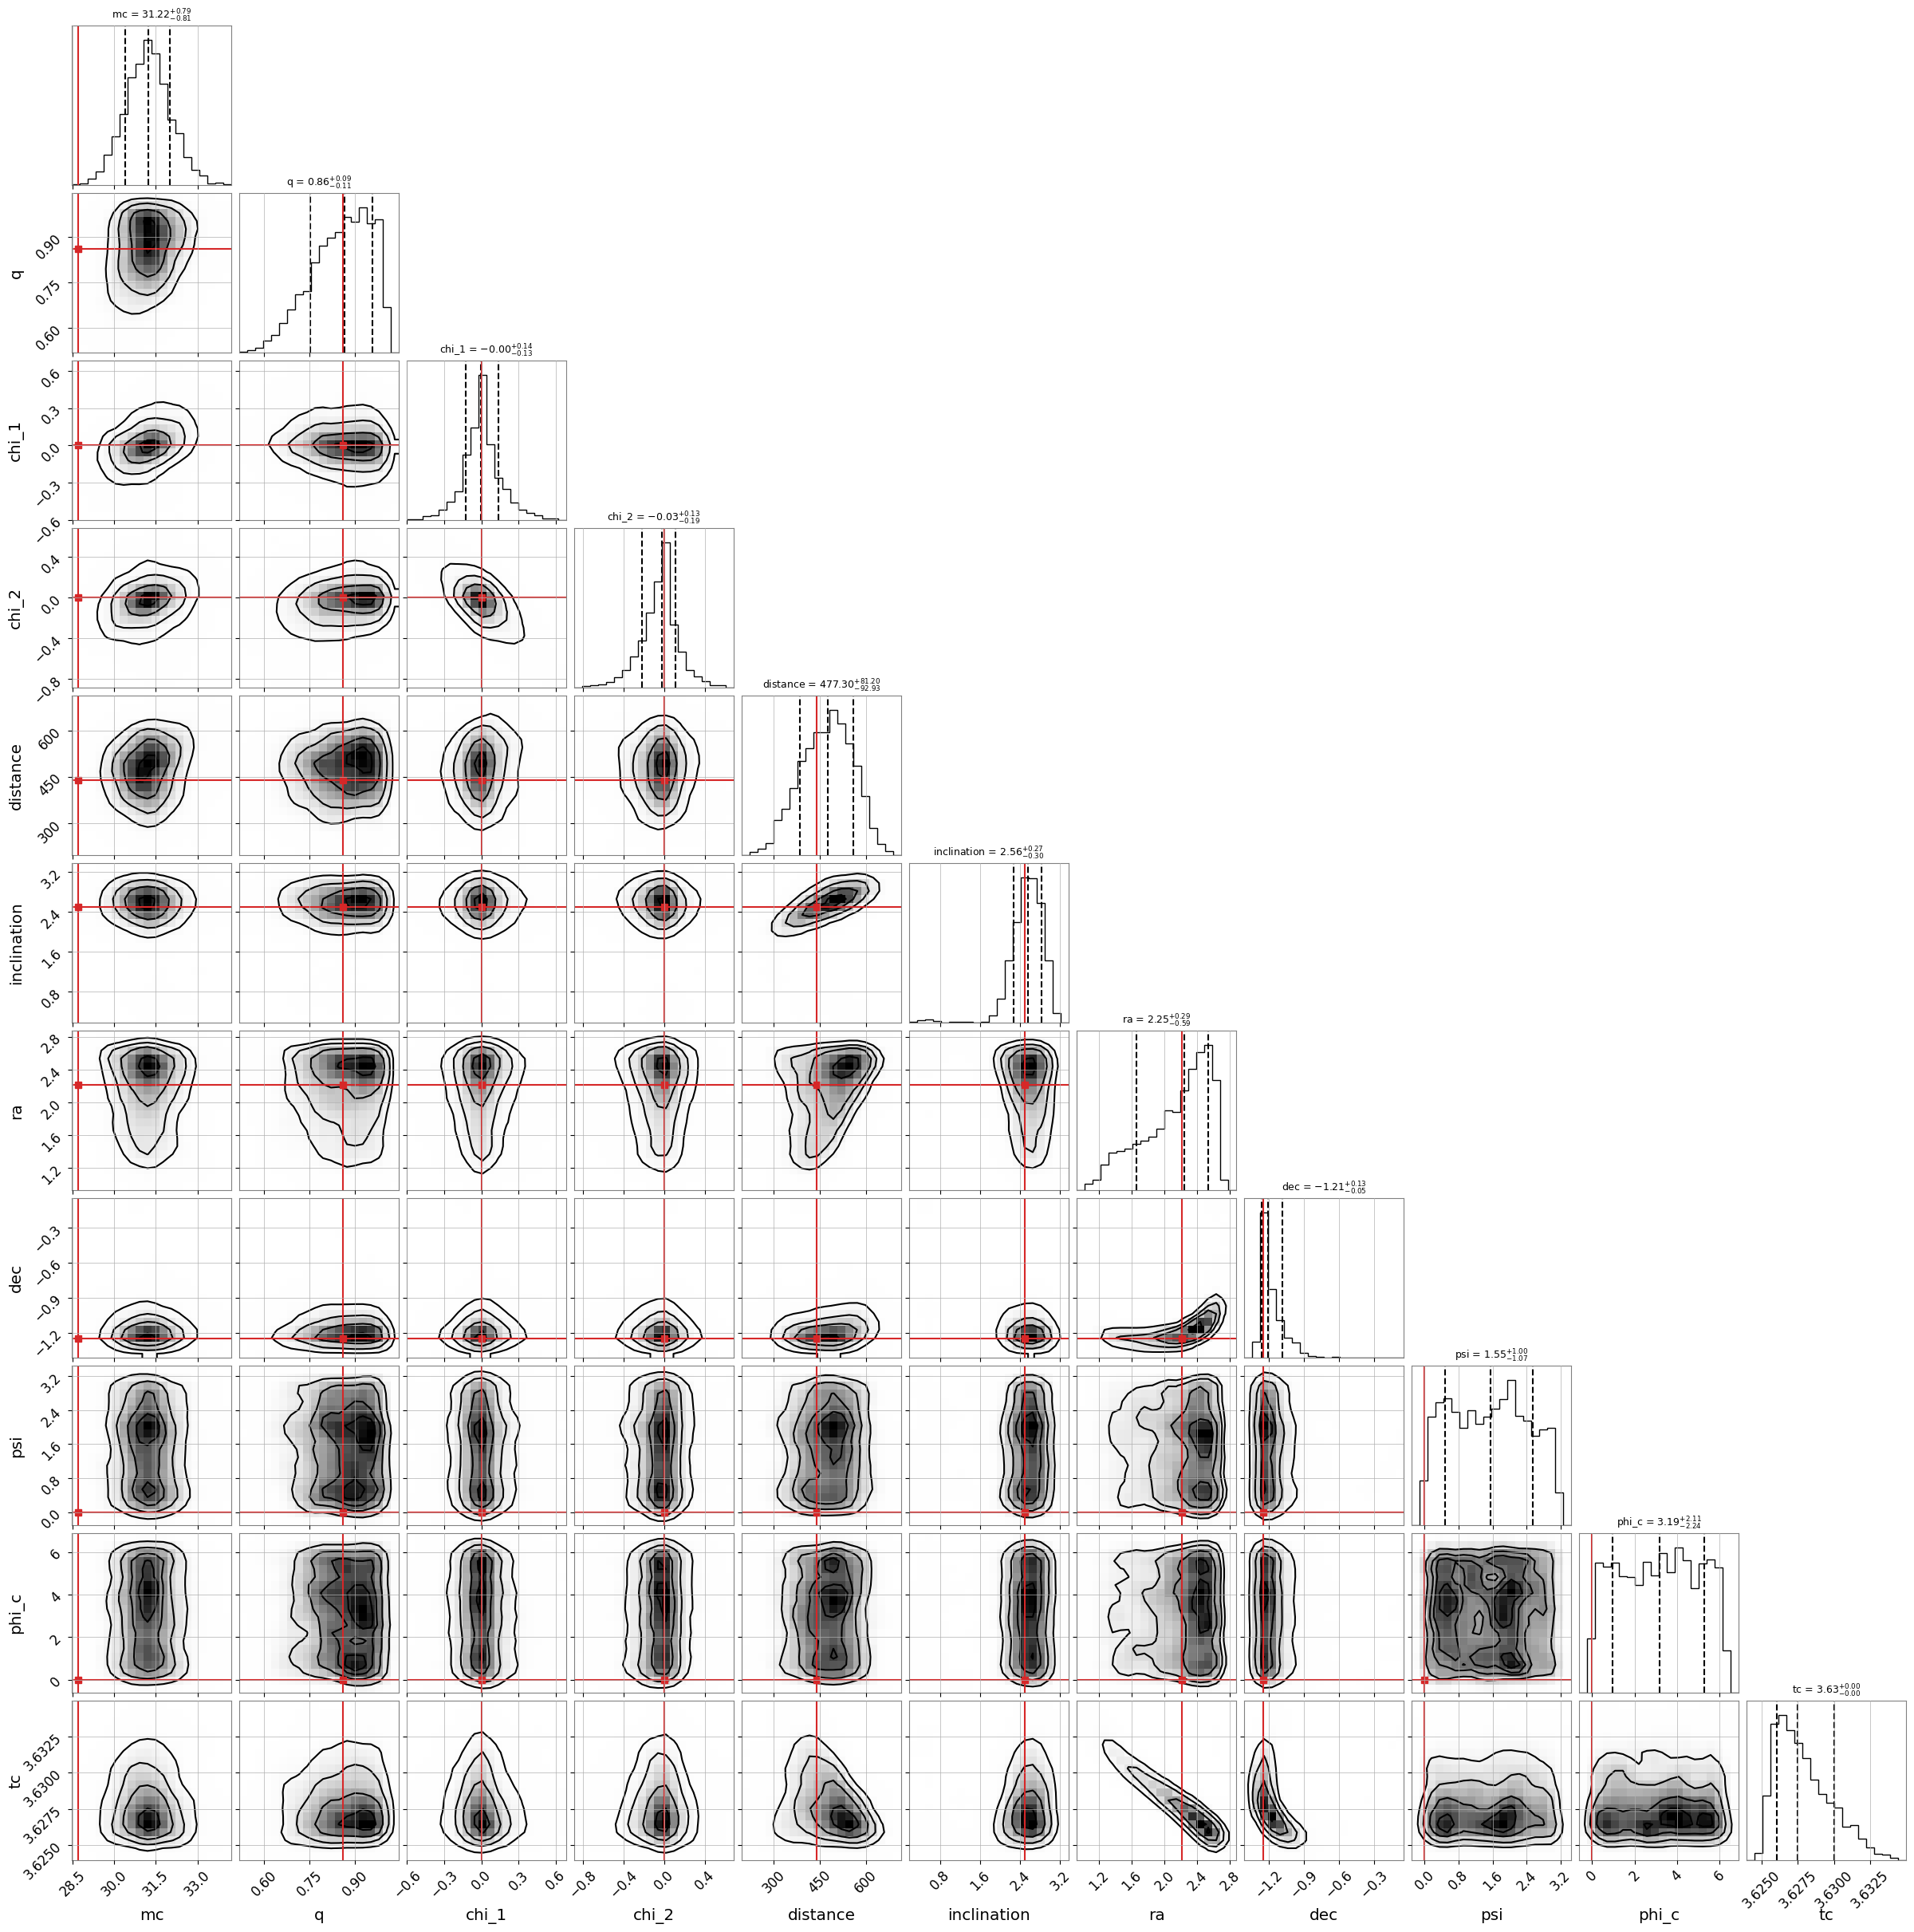

In [32]:
import corner, matplotlib.pyplot as plt
names = list(PARAM_BOUNDS)
X = np.column_stack([post[n] for n in names])
lo, hi = np.percentile(X, 0.2, axis=0), np.percentile(X, 99.8, axis=0)
pad = 0.1 * (hi - lo)
fig = corner.corner(X, labels=names, range=list(zip(lo - pad, hi + pad)),
                    truths=[PUBLISHED_MEDIAN[n] for n in names], truth_color="C3",
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_kwargs={"fontsize": 9},
                    plot_datapoints=False, smooth=0.9)
fig.savefig(f"{RUN_DIR}/corner.png", dpi=110, bbox_inches="tight")
plt.show()

## 9. Comparison with GWTC-2.1 (visual)

In [19]:
!pip install -q pesummary

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 MB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.2/168.2 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.2 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 50.0.2 which is incompatible.


In [33]:
# ── GWTC-2.1 release file (Zenodo 6513631); upload it manually if the download fails ──
import os, subprocess
GWTC_FILE = "IGWN-GWTC2p1-v2-GW150914_095045_PEDataRelease_mixed_cosmo.h5"
if not os.path.exists(GWTC_FILE):
    url = f"https://zenodo.org/records/6513631/files/{GWTC_FILE}?download=1"
    r = subprocess.run(["wget", "-q", "-O", GWTC_FILE, url])
    if r.returncode != 0 or os.path.getsize(GWTC_FILE) < 1e6:
        os.remove(GWTC_FILE) if os.path.exists(GWTC_FILE) else None
        raise FileNotFoundError(f"download failed — upload {GWTC_FILE} to /content manually")
print("GWTC-2.1 file:", GWTC_FILE, f"{os.path.getsize(GWTC_FILE)/1e6:.0f} MB")

GWTC-2.1 file: IGWN-GWTC2p1-v2-GW150914_095045_PEDataRelease_mixed_cosmo.h5 134 MB


In [34]:
# ── GWTC-2.1 release file (Zenodo 6513631); upload it manually if the download fails ──
import os, subprocess
GWTC_FILE = "IGWN-GWTC2p1-v2-GW150914_095045_PEDataRelease_mixed_cosmo.h5"
if not os.path.exists(GWTC_FILE):
    url = f"https://zenodo.org/records/6513631/files/{GWTC_FILE}?download=1"
    r = subprocess.run(["wget", "-q", "-O", GWTC_FILE, url])
    if r.returncode != 0 or os.path.getsize(GWTC_FILE) < 1e6:
        os.remove(GWTC_FILE) if os.path.exists(GWTC_FILE) else None
        raise FileNotFoundError(f"download failed — upload {GWTC_FILE} to /content manually")
print("GWTC-2.1 file:", GWTC_FILE, f"{os.path.getsize(GWTC_FILE)/1e6:.0f} MB")

GWTC-2.1 file: IGWN-GWTC2p1-v2-GW150914_095045_PEDataRelease_mixed_cosmo.h5 134 MB


2026-11-17  14:25:58 PESummary WARNING : Could not find f_start in input file and one was not passed from the command line. Using 20.0Hz as default


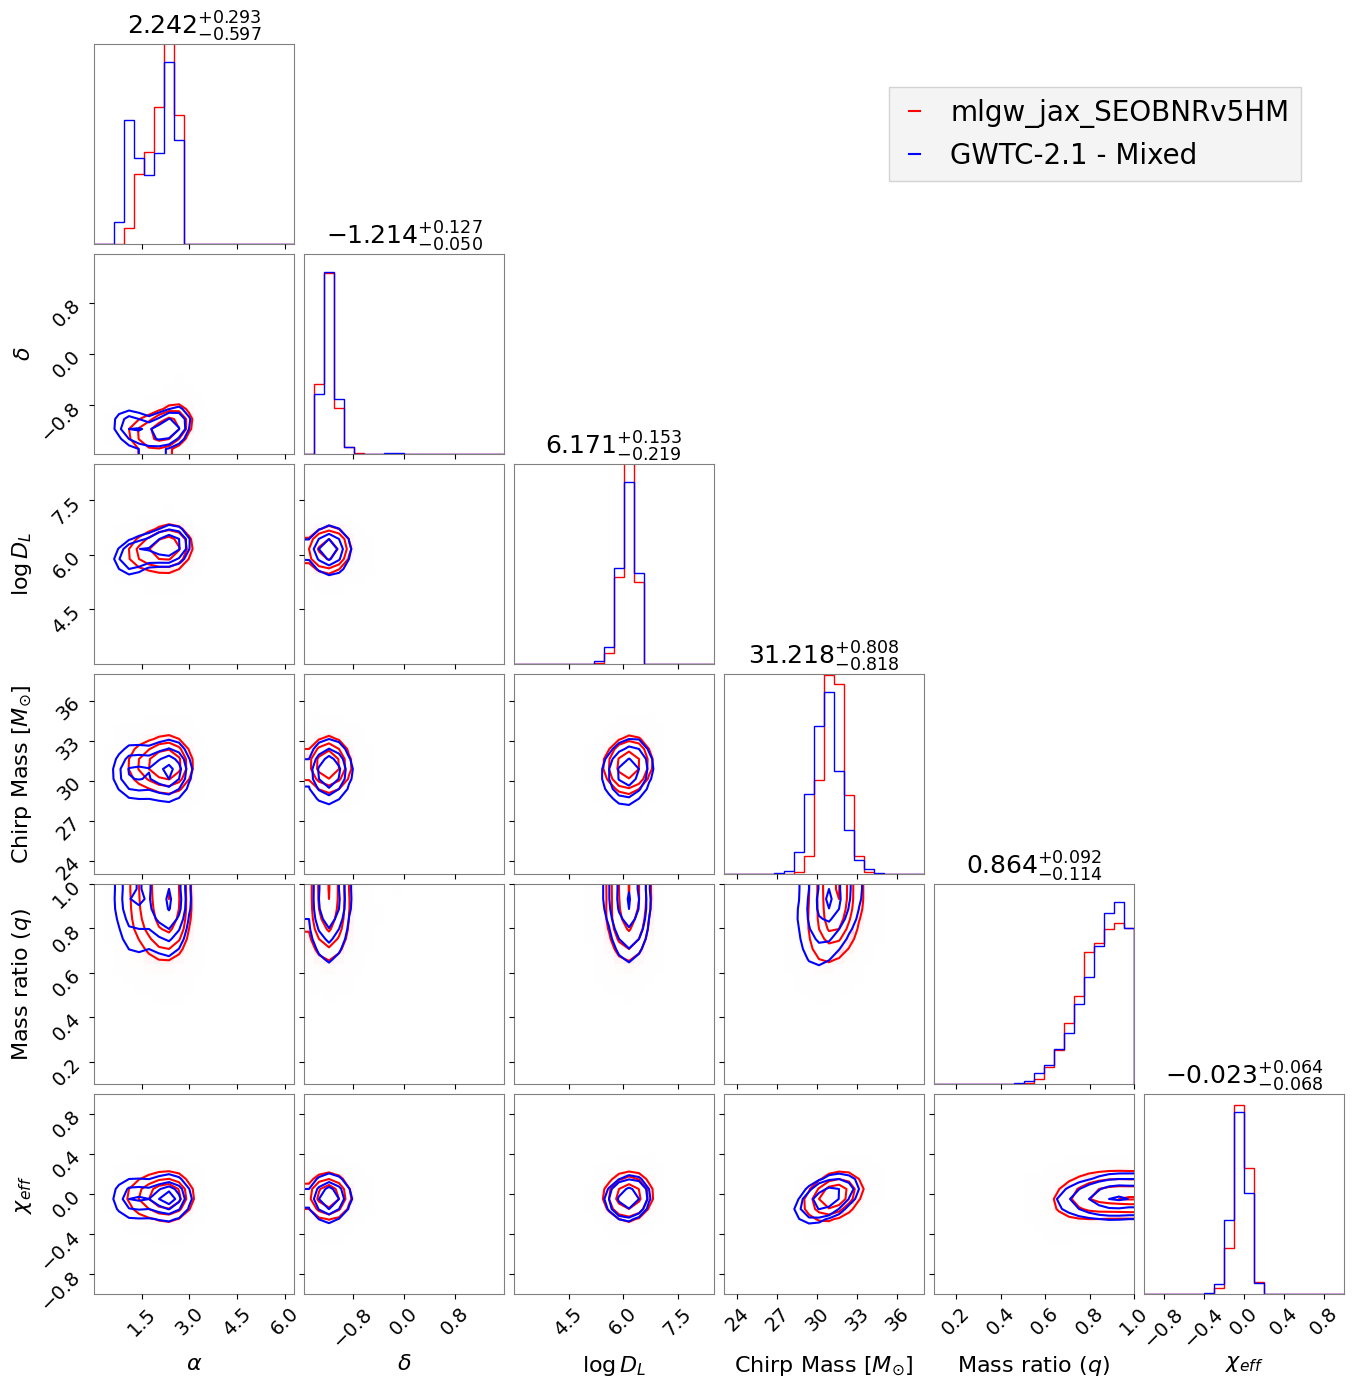

In [35]:
import corner
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
from pesummary.io import read

# Reload the data into a different variable name because 'data' was overwritten by a numpy array earlier
filename = GWTC_FILE
pe_data = read(filename, disable_prior=True)

# 1. Extract C01:Mixed data from GWTC-2.1
samples_mixed = pe_data.samples_dict['C01:Mixed']

# Extracting and converting relevant parameters
mixed_mc = np.array(samples_mixed['chirp_mass'])
mixed_q = np.array(samples_mixed['mass_ratio'])
mixed_ra = np.mod(np.array(samples_mixed['ra']), 2*np.pi)

# Handle declination/zenith correctly
if 'zenith' in samples_mixed.keys():
    mixed_dec = np.pi/2 - np.array(samples_mixed['zenith'])
else:
    mixed_dec = np.array(samples_mixed['dec'])

mixed_logdl = np.log(np.array(samples_mixed['luminosity_distance']))
mixed_chi_eff = np.array(samples_mixed['chi_eff'])

# Stack the data
mixed_data = np.column_stack([mixed_ra, mixed_dec, mixed_logdl, mixed_mc, mixed_q, mixed_chi_eff])

# 2. Extract MLGW-JAX SEOBNRv5HM data
v5_ra = np.array(result.posterior_samples['ra'])
v5_dec = np.array(result.posterior_samples['dec'])
v5_logdl = np.log(np.array(result.posterior_samples['distance']))
v5_mc = np.array(result.posterior_samples['mc'])
v5_q = np.array(result.posterior_samples['q'])
v5_chi_1 = np.array(result.posterior_samples['chi_1'])
v5_chi_2 = np.array(result.posterior_samples['chi_2'])

# Calculate chi_eff: (m1*chi_1 + m2*chi_2)/(m1+m2) = (q*chi_1 + chi_2)/(1+q) where q = m2/m1 <= 1
v5_chi_eff = (v5_q * v5_chi_1 + v5_chi_2) / (1.0 + v5_q)

# Stack the MLGW-JAX data (v5_q is already m2/m1 <= 1, no need to invert)
v5_data = np.column_stack([v5_ra, v5_dec, v5_logdl, v5_mc, v5_q, v5_chi_eff])

# 3. Define labels and standardized ranges
labels_comp = [r'$\alpha$', r'$\delta$', r'$\log{D_{L}}$', r'Chirp Mass $[M_{\odot}]$', r'Mass ratio ($q$)', r'$\chi_{eff}$']
ranges_comp = [
    (0, 2*np.pi),        # alpha (RA)
    (-np.pi/2, np.pi/2), # delta (Dec)
    (3.0, 8.5),          # logDL
    (23.0, 38.0),        # Mc
    (0.1, 1.0),          # q
    (-1, 1)              # chi_eff
]

# Set desired font sizes
LABEL_FONT = 16
TITLE_FONT = 18
TICK_FONT = 14
LEGEND_FONT = 20

# 4. Create the Comparison Corner Plot
# MLGW-JAX SEOBNRv5HM (Red) - Base layer
fig = corner.corner(
    v5_data[-6000:],
    labels=labels_comp,
    range=ranges_comp,
    smooth=1,
    color='red',
    hist_kwargs={'density': True},
    label_kwargs={'fontsize': LABEL_FONT},
    title_kwargs={'fontsize': TITLE_FONT},
    plot_contours=True,
    show_titles=True,
    plot_datapoints=False,
    title_fmt='.3f'
)

# GWTC-2.1 Mixed (Blue) - Overlay
corner.corner(
    mixed_data,
    fig=fig,
    range=ranges_comp,
    smooth=0.9,
    color='blue',
    hist_kwargs={'density': True},
    plot_contours=True,
    fill_contours=False,   # Do not fill contours
    plot_datapoints=False, # Do not plot datapoints
    plot_density=False     # Turn off 2D density color filling
)

# Clean up titles to only show numbers and increase tick font sizes
ndim = len(labels_comp)
axes = np.array(fig.axes).reshape((ndim, ndim))
for i in range(ndim):
    # Extract and modify title on the diagonal
    ax_diag = axes[i, i]
    title = ax_diag.get_title()
    if "=" in title:
        ax_diag.set_title(title.split("=")[-1].strip(), fontsize=TITLE_FONT)

    # Update tick labels size for all axes
    for j in range(ndim):
        axes[i, j].tick_params(axis='both', which='major', labelsize=TICK_FONT)

# 5. Add Legends and Title
proxy_v5 = mlines.Line2D([], [], color='red', label='mlgw_jax_SEOBNRv5HM')
proxy_mixed = mlines.Line2D([], [], color='blue', label='GWTC-2.1 - Mixed')

fig.legend(handles=[proxy_v5, proxy_mixed], loc='upper right', bbox_to_anchor=(0.95, 0.95), fontsize=LEGEND_FONT, frameon=True, facecolor='#f4f4f4', edgecolor='lightgrey', framealpha=1.0)

# Remove grid lines
for ax in fig.axes:
    ax.grid(False)

plt.savefig('corner_fig_no_incl.png')
plt.show()

2026-11-17  14:26:39 PESummary WARNING : Could not find f_start in input file and one was not passed from the command line. Using 20.0Hz as default


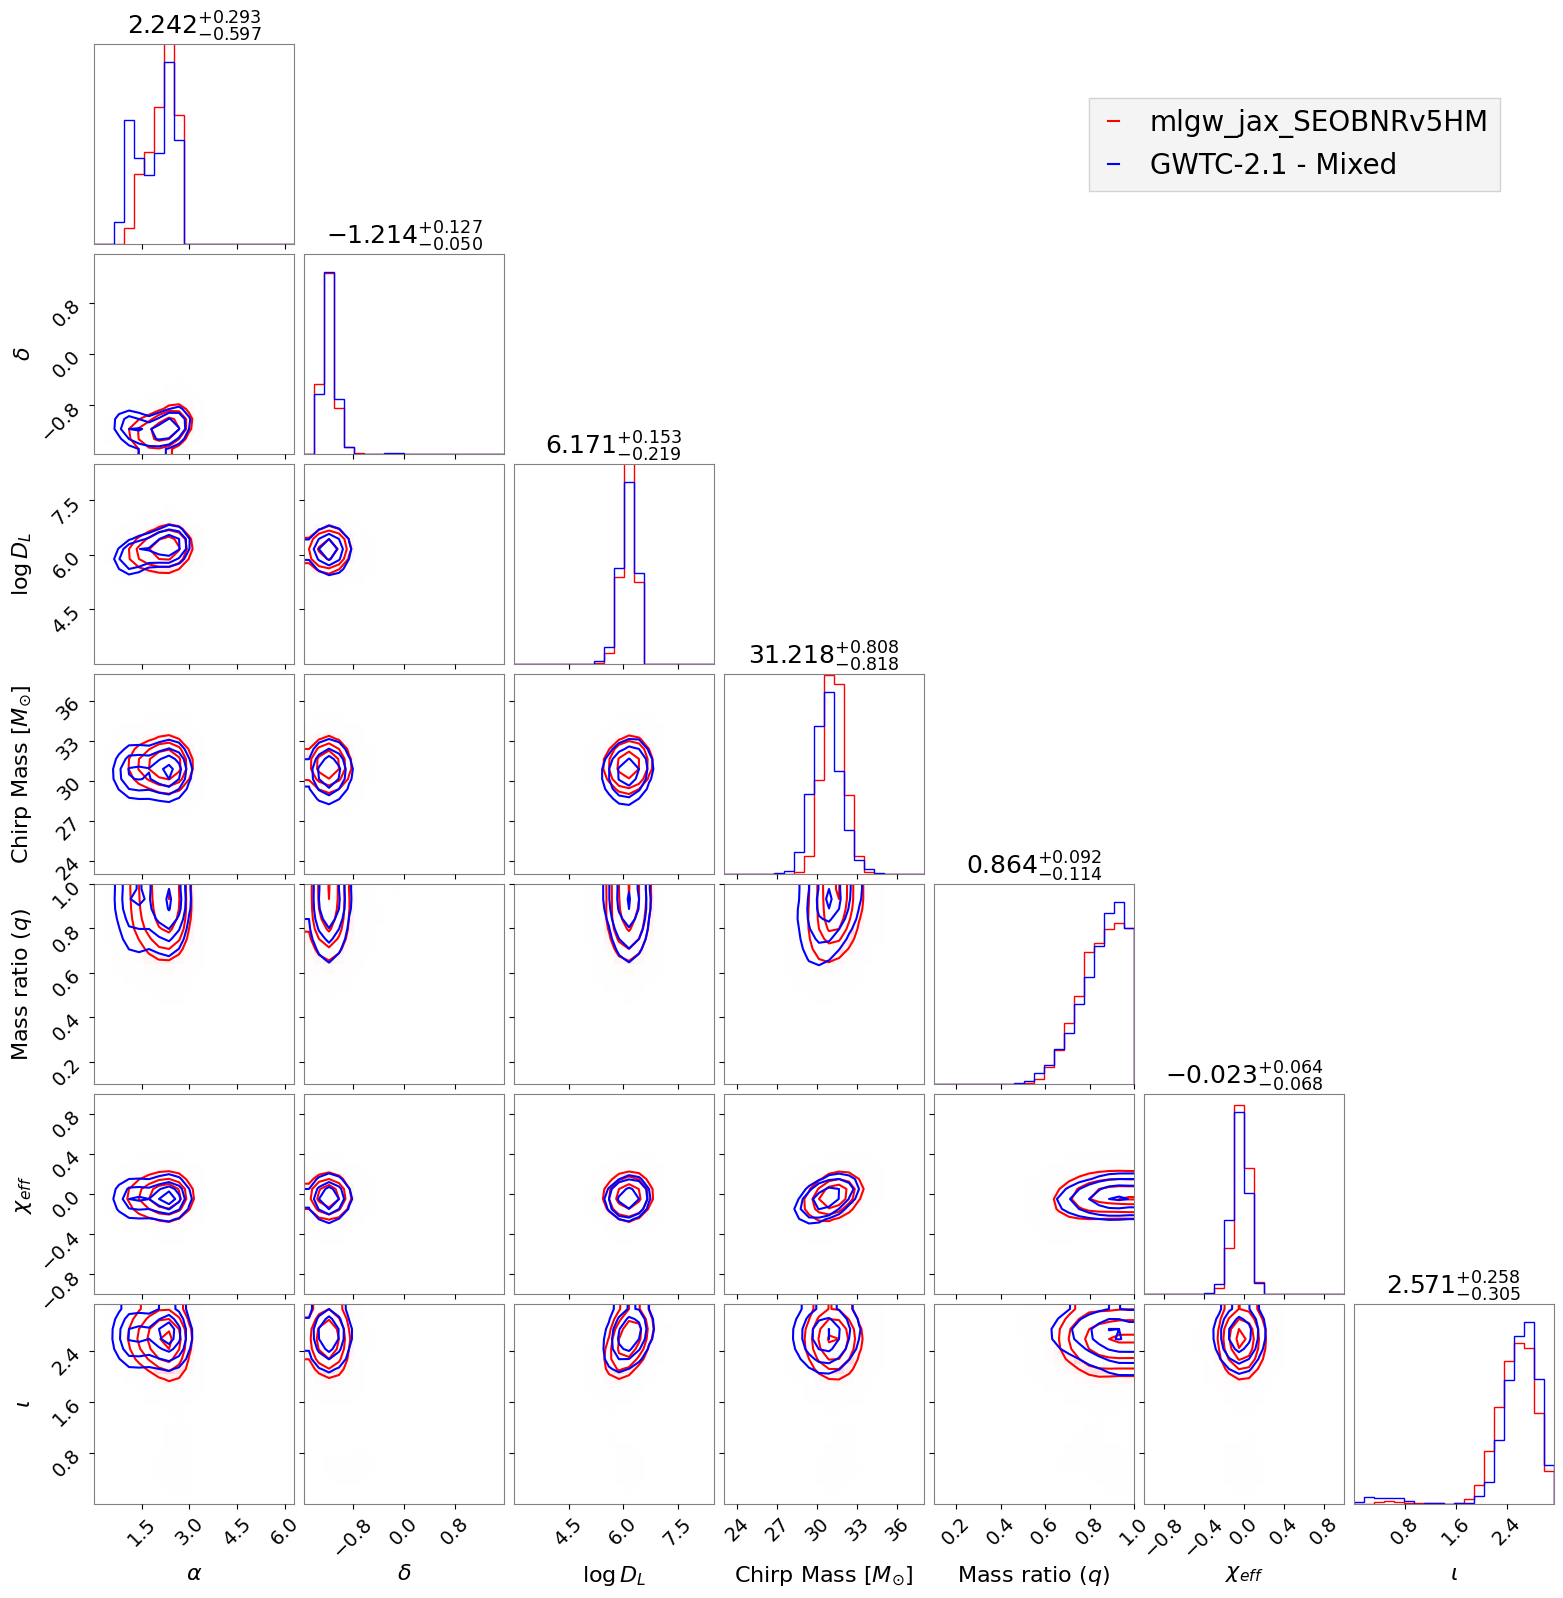

In [36]:
import corner
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
from pesummary.io import read

# Reload the data into a different variable name because 'data' was overwritten by a numpy array earlier
filename = GWTC_FILE
pe_data = read(filename, disable_prior=True)

# 1. Extract C01:Mixed data from GWTC-2.1
samples_mixed = pe_data.samples_dict['C01:Mixed']

# Extracting and converting relevant parameters
mixed_mc = np.array(samples_mixed['chirp_mass'])
mixed_q = np.array(samples_mixed['mass_ratio'])
mixed_ra = np.mod(np.array(samples_mixed['ra']), 2*np.pi)

# Handle declination/zenith correctly
if 'zenith' in samples_mixed.keys():
    mixed_dec = np.pi/2 - np.array(samples_mixed['zenith'])
else:
    mixed_dec = np.array(samples_mixed['dec'])

mixed_logdl = np.log(np.array(samples_mixed['luminosity_distance']))
mixed_chi_eff = np.array(samples_mixed['chi_eff'])
mixed_inclination = np.array(samples_mixed['iota']) if 'iota' in samples_mixed.keys() else np.array(samples_mixed['theta_jn'])

# Stack the data
mixed_data = np.column_stack([mixed_ra, mixed_dec, mixed_logdl, mixed_mc, mixed_q, mixed_chi_eff, mixed_inclination])

# 2. Extract MLGW-JAX SEOBNRv5HM data
v5_ra = np.array(result.posterior_samples['ra'])
v5_dec = np.array(result.posterior_samples['dec'])
v5_logdl = np.log(np.array(result.posterior_samples['distance']))
v5_mc = np.array(result.posterior_samples['mc'])
v5_q = np.array(result.posterior_samples['q'])
v5_chi_1 = np.array(result.posterior_samples['chi_1'])
v5_chi_2 = np.array(result.posterior_samples['chi_2'])
v5_inclination = np.array(result.posterior_samples['inclination'])

# Calculate chi_eff: (m1*chi_1 + m2*chi_2)/(m1+m2) = (q*chi_1 + chi_2)/(1+q) where q = m2/m1 <= 1
v5_chi_eff = (v5_q * v5_chi_1 + v5_chi_2) / (1.0 + v5_q)

# Stack the MLGW-JAX data (v5_q is already m2/m1 <= 1, no need to invert)
v5_data = np.column_stack([v5_ra, v5_dec, v5_logdl, v5_mc, v5_q, v5_chi_eff, v5_inclination])

# 3. Define labels and standardized ranges
labels_comp = [r'$\alpha$', r'$\delta$', r'$\log{D_{L}}$', r'Chirp Mass $[M_{\odot}]$', r'Mass ratio ($q$)', r'$\chi_{eff}$', r'$\iota$']
ranges_comp = [
    (0, 2*np.pi),        # alpha (RA)
    (-np.pi/2, np.pi/2), # delta (Dec)
    (3.0, 8.5),          # logDL
    (23.0, 38.0),        # Mc
    (0.1, 1.0),          # q
    (-1, 1),             # chi_eff
    (0, np.pi)           # inclination
]

# Set desired font sizes
LABEL_FONT = 16
TITLE_FONT = 18
TICK_FONT = 14
LEGEND_FONT = 20

# 4. Create the Comparison Corner Plot
# MLGW-JAX SEOBNRv5HM (Red) - Base layer
fig = corner.corner(
    v5_data[-6000:],
    labels=labels_comp,
    range=ranges_comp,
    smooth=1,
    color='red',
    hist_kwargs={'density': True},
    label_kwargs={'fontsize': LABEL_FONT},
    title_kwargs={'fontsize': TITLE_FONT},
    plot_contours=True,
    show_titles=True,
    plot_datapoints=False,
    title_fmt='.3f'
)

# GWTC-2.1 Mixed (Blue) - Overlay
corner.corner(
    mixed_data,
    fig=fig,
    range=ranges_comp,
    smooth=0.9,
    color='blue',
    hist_kwargs={'density': True},
    plot_contours=True,
    fill_contours=False,   # Do not fill contours
    plot_datapoints=False, # Do not plot datapoints
    plot_density=False     # Turn off 2D density color filling
)

# Clean up titles to only show numbers and increase tick font sizes
ndim = len(labels_comp)
axes = np.array(fig.axes).reshape((ndim, ndim))
for i in range(ndim):
    # Extract and modify title on the diagonal
    ax_diag = axes[i, i]
    title = ax_diag.get_title()
    if "=" in title:
        ax_diag.set_title(title.split("=")[-1].strip(), fontsize=TITLE_FONT)

    # Update tick labels size for all axes
    for j in range(ndim):
        axes[i, j].tick_params(axis='both', which='major', labelsize=TICK_FONT)

# 5. Add Legends and Title
proxy_v5 = mlines.Line2D([], [], color='red', label='mlgw_jax_SEOBNRv5HM')
proxy_mixed = mlines.Line2D([], [], color='blue', label='GWTC-2.1 - Mixed')

fig.legend(handles=[proxy_v5, proxy_mixed], loc='upper right', bbox_to_anchor=(0.95, 0.95), fontsize=LEGEND_FONT, frameon=True, facecolor='#f4f4f4', edgecolor='lightgrey', framealpha=1.0)

# Remove grid lines
for ax in fig.axes:
    ax.grid(False)

plt.savefig('corner_fig_with_incl.png')
plt.show()

## 10. JS divergence vs GWTC-2.1 (referee comment 1b)

LVK convention: 1-D Gaussian KDEs on a shared grid (reflected at hard bounds, wrapped for ra), JSD in
**bits**, bootstrap median and 90% interval, plus the split-half noise floor of our own run.
**Caveat (as the referee notes):** GWTC-2.1 uses precessing higher-mode models, a different sampler,
BayesWave PSDs and calibration marginalisation, so this comparison mixes all of those effects; the
surrogate/sampler-only numbers come from the injection benchmarks (`examples/referee_response/jsd_results/`).

In [37]:
from scipy.stats import gaussian_kde
from pesummary.io import read as pes_read

def _pdf(x, grid, bounds=None, period=None):
    k = gaussian_kde(x); p = k(grid)
    if period: p += k(grid - period) + k(grid + period)
    elif bounds:
        if bounds[0] is not None: p += k(2 * bounds[0] - grid)
        if bounds[1] is not None: p += k(2 * bounds[1] - grid)
    p = np.clip(p, 0, None); return p / np.trapz(p, grid)

def jsd_bits(x, y, bounds=None, period=None, n=2000):
    span = max(x.max(), y.max()) - min(x.min(), y.min())
    lo, hi = min(x.min(), y.min()) - 0.1 * span, max(x.max(), y.max()) + 0.1 * span
    if period: lo, hi = 0.0, period
    elif bounds:
        lo = max(lo, bounds[0]) if bounds[0] is not None else lo
        hi = min(hi, bounds[1]) if bounds[1] is not None else hi
    g = np.linspace(lo, hi, n); p, q = _pdf(x, g, bounds, period), _pdf(y, g, bounds, period); m = 0.5 * (p + q)
    kl = lambda a, b: np.trapz(np.where(a > 0, a * np.log2(np.where(a > 0, a, 1) / b), 0), g)
    return float(np.clip(0.5 * kl(p, m) + 0.5 * kl(q, m), 0, 1))

def boot(x, y, rng, nb=40, ns=3000, **kw):
    ns = min(ns, len(x), len(y))
    return np.percentile([jsd_bits(rng.choice(x, ns, False), rng.choice(y, ns, False), **kw) for _ in range(nb)], [5, 50, 95])

ours = dict(mc=post["mc"], q=post["q"], chi_eff=(post["chi_1"] + post["q"] * post["chi_2"]) / (1 + post["q"]),
            distance=post["distance"], theta_jn=post["inclination"], ra=np.mod(post["ra"], 2 * np.pi), dec=post["dec"])
BND = dict(q=(None, 1.0), chi_eff=(-1.0, 1.0), theta_jn=(0.0, np.pi))
pe = pes_read(GWTC_FILE, disable_prior=True)
rng = np.random.default_rng(0)
table = {}
for label in ["C01:Mixed", "C01:IMRPhenomXPHM", "C01:SEOBNRv4PHM"]:
    if label not in pe.samples_dict: continue
    s = pe.samples_dict[label]
    ref = dict(mc=np.asarray(s["chirp_mass"]), q=np.asarray(s["mass_ratio"]), chi_eff=np.asarray(s["chi_eff"]),
               distance=np.asarray(s["luminosity_distance"]), theta_jn=np.asarray(s["theta_jn"]),
               ra=np.mod(np.asarray(s["ra"]), 2 * np.pi), dec=np.asarray(s["dec"]))
    print(f"\n=== mlgw_bbh (this run) vs GWTC-2.1 {label}")
    print(f"{'param':10s} {'JSD [bits]':>10s} {'90% CI':>19s}  {'floor':>7s}")
    table[label] = {}
    for n in ours:
        kw = dict(period=2 * np.pi) if n == "ra" else dict(bounds=BND.get(n))
        lo, med, hi = boot(ours[n], ref[n], rng, **kw)
        perm = rng.permutation(len(ours[n])); h = min(3000, len(perm) // 2)
        floor = jsd_bits(ours[n][perm[:h]], ours[n][perm[h:2 * h]], **kw)
        table[label][n] = dict(jsd_median=med, jsd_5=lo, jsd_95=hi, floor=floor)
        print(f"{n:10s} {med:10.4f} [{lo:8.4f},{hi:8.4f}]  {floor:7.4f}")
json.dump(table, open(f"{RUN_DIR}/jsd_vs_gwtc2p1.json", "w"), indent=2)
print("\nsaved", f"{RUN_DIR}/jsd_vs_gwtc2p1.json")

2026-11-17  14:27:22 PESummary WARNING : Could not find f_start in input file and one was not passed from the command line. Using 20.0Hz as default



=== mlgw_bbh (this run) vs GWTC-2.1 C01:Mixed
param      JSD [bits]              90% CI    floor


/tmp/ipython-input-1416555370.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p = np.clip(p, 0, None); return p / np.trapz(p, grid)
/tmp/ipython-input-1416555370.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  kl = lambda a, b: np.trapz(np.where(a > 0, a * np.log2(np.where(a > 0, a, 1) / b), 0), g)


mc             0.0738 [  0.0682,  0.0791]   0.0007
q              0.0036 [  0.0025,  0.0053]   0.0007
chi_eff        0.0424 [  0.0404,  0.0452]   0.0008
distance       0.0054 [  0.0042,  0.0069]   0.0012
theta_jn       0.0462 [  0.0429,  0.0500]   0.0022
ra             0.0840 [  0.0798,  0.0868]   0.0005
dec            0.0106 [  0.0092,  0.0131]   0.0023

=== mlgw_bbh (this run) vs GWTC-2.1 C01:IMRPhenomXPHM
param      JSD [bits]              90% CI    floor
mc             0.1368 [  0.1254,  0.1455]   0.0006
q              0.0140 [  0.0109,  0.0173]   0.0004
chi_eff        0.0818 [  0.0760,  0.0877]   0.0006
distance       0.0090 [  0.0053,  0.0116]   0.0004
theta_jn       0.0428 [  0.0358,  0.0476]   0.0020
ra             0.1301 [  0.1171,  0.1383]   0.0003
dec            0.0056 [  0.0041,  0.0069]   0.0017

=== mlgw_bbh (this run) vs GWTC-2.1 C01:SEOBNRv4PHM
param      JSD [bits]              90% CI    floor
mc             0.0366 [  0.0303,  0.0421]   0.0009
q              0.0310 [  